In [ ]:
!pip install -q google-genai pandas matplotlib

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import time
import os

In [ ]:
from google import genai
from google.colab import userdata

# Retrieve the API key using the name of the secret you defined in Colab Secrets
# Make sure you have added a secret named 'GEMINI_API_KEY' in the Secrets tab (key icon on the left sidebar)
api_key = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=api_key)

print("Gemini API connected successfully!")

Gemini API connected successfully!


In [ ]:

import time

MIN_REQUEST_INTERVAL = 5
MAX_RETRIES = 5
last_request_time = 0


def call_llm(prompt):
    global last_request_time

    for attempt in range(MAX_RETRIES):
        try:
            # Space out requests
            elapsed = time.monotonic() - last_request_time

            if elapsed < MIN_REQUEST_INTERVAL:
                time.sleep(MIN_REQUEST_INTERVAL - elapsed)

            last_request_time = time.monotonic()

            response = client.models.generate_content(
                model="gemini-3.5-flash-lite",
                contents=prompt
            )

            if not response.text:
                print("Empty response received from Gemini.")
                return None

            return response.text.strip()

        except Exception as e:
            error_message = str(e)

            # Retry rate-limit and temporary server errors
            if "429" in error_message or "RESOURCE_EXHAUSTED" in error_message or "503" in error_message:

                if attempt == MAX_RETRIES - 1:
                    print(f"Failed after {MAX_RETRIES} attempts: {e}")
                    return None

                wait_time = min(5 * (2 ** attempt), 60)

                print(
                    f"Temporary API error. "
                    f"Retrying in {wait_time} seconds..."
                )

                time.sleep(wait_time)

            else:
                print("Error:", e)
                return None

    return None


In [ ]:
answer = call_llm("What is the capital of Australia?")

print("Answer:", answer)

Answer: The capital of Australia is **Canberra**.


In [ ]:
for model in client.models.list():
    print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/l

In [ ]:
data = [
    {
        "id": 1,
        "question": "What is the capital of Australia?",
        "ground_truth": "Canberra",
        "category": "Geography"
    },

    {
        "id": 2,
        "question": "Who discovered penicillin?",
        "ground_truth": "Alexander Fleming",
        "category": "Science"
    },

    {
        "id": 3,
        "question": "What is the largest planet in our Solar System?",
        "ground_truth": "Jupiter",
        "category": "Science"
    },

    {
        "id": 4,
        "question": "Who wrote Hamlet?",
        "ground_truth": "William Shakespeare",
        "category": "Literature"
    },

    {
        "id": 5,
        "question": "In which year did World War II end?",
        "ground_truth": "1945",
        "category": "History"
    },

    {
        "id": 6,
        "question": "What is the chemical symbol for gold?",
        "ground_truth": "Au",
        "category": "Science"
    },

    {
        "id": 7,
        "question": "Which is the largest ocean on Earth?",
        "ground_truth": "Pacific Ocean",
        "category": "Geography"
    },

    {
        "id": 8,
        "question": "Who painted the Mona Lisa?",
        "ground_truth": "Leonardo da Vinci",
        "category": "Art"
    },

    {
        "id": 9,
        "question": "What is the smallest prime number?",
        "ground_truth": "2",
        "category": "Mathematics"
    },

    {
        "id": 10,
        "question": "Which planet is known as the Red Planet?",
        "ground_truth": "Mars",
        "category": "Science"
    },

    {
        "id": 11,
        "question": "Who was the first President of the United States?",
        "ground_truth": "George Washington",
        "category": "History"
    },

    {
        "id": 12,
        "question": "What is the capital of Japan?",
        "ground_truth": "Tokyo",
        "category": "Geography"
    },

    {
        "id": 13,
        "question": "What is the hardest natural substance?",
        "ground_truth": "Diamond",
        "category": "Science"
    },

    {
        "id": 14,
        "question": "Who developed the theory of relativity?",
        "ground_truth": "Albert Einstein",
        "category": "Science"
    },

    {
        "id": 15,
        "question": "Which continent is Egypt located in?",
        "ground_truth": "Africa",
        "category": "Geography"
    },

    {
        "id": 16,
        "question": "What is the currency of Japan?",
        "ground_truth": "Yen",
        "category": "General Knowledge"
    },

    {
        "id": 17,
        "question": "Who wrote Romeo and Juliet?",
        "ground_truth": "William Shakespeare",
        "category": "Literature"
    },

    {
        "id": 18,
        "question": "What is the boiling point of water at sea level in Celsius?",
        "ground_truth": "100",
        "category": "Science"
    },

    {
        "id": 19,
        "question": "Which organ pumps blood throughout the human body?",
        "ground_truth": "Heart",
        "category": "Biology"
    },

    {
        "id": 20,
        "question": "What is the capital of France?",
        "ground_truth": "Paris",
        "category": "Geography"
    },

    {
        "id": 21,
        "question": "What is the capital of Canada?",
        "ground_truth": "Ottawa",
        "category": "Geography"
    },

    {
        "id": 22,
        "question": "Which gas do plants absorb during photosynthesis?",
        "ground_truth": "Carbon dioxide",
        "category": "Science"
    },

    {
        "id": 23,
        "question": "Who invented the telephone?",
        "ground_truth": "Alexander Graham Bell",
        "category": "Science"
    },

    {
        "id": 24,
        "question": "What is the largest mammal in the world?",
        "ground_truth": "Blue whale",
        "category": "Biology"
    },

    {
        "id": 25,
        "question": "How many sides does a hexagon have?",
        "ground_truth": "6",
        "category": "Mathematics"
    },

    {
        "id": 26,
        "question": "Which country is famous for the Great Wall?",
        "ground_truth": "China",
        "category": "Geography"
    },

    {
        "id": 27,
        "question": "Who wrote the novel Pride and Prejudice?",
        "ground_truth": "Jane Austen",
        "category": "Literature"
    },

    {
        "id": 28,
        "question": "What is the chemical symbol for oxygen?",
        "ground_truth": "O",
        "category": "Science"
    },

    {
        "id": 29,
        "question": "In which year did India gain independence?",
        "ground_truth": "1947",
        "category": "History"
    },

    {
        "id": 30,
        "question": "Which is the closest star to Earth?",
        "ground_truth": "The Sun",
        "category": "Science"
    },

    {
        "id": 31,
        "question": "What is the capital of Italy?",
        "ground_truth": "Rome",
        "category": "Geography"
    },

    {
        "id": 32,
        "question": "How many bones are there in an average adult human body?",
        "ground_truth": "206",
        "category": "Biology"
    },

    {
        "id": 33,
        "question": "Who painted the ceiling of the Sistine Chapel?",
        "ground_truth": "Michelangelo",
        "category": "Art"
    },

    {
        "id": 34,
        "question": "What is the square root of 144?",
        "ground_truth": "12",
        "category": "Mathematics"
    },

    {
        "id": 35,
        "question": "Which is the largest continent by area?",
        "ground_truth": "Asia",
        "category": "Geography"
    },

    {
        "id": 36,
        "question": "What is the process by which plants make their own food?",
        "ground_truth": "Photosynthesis",
        "category": "Biology"
    },

    {
        "id": 37,
        "question": "Who was the first person to walk on the Moon?",
        "ground_truth": "Neil Armstrong",
        "category": "History"
    },

    {
        "id": 38,
        "question": "What is the currency of the United Kingdom?",
        "ground_truth": "Pound sterling",
        "category": "General Knowledge"
    },

    {
        "id": 39,
        "question": "Which instrument is used to measure temperature?",
        "ground_truth": "Thermometer",
        "category": "Science"
    },

    {
        "id": 40,
        "question": "What is the fastest land animal?",
        "ground_truth": "Cheetah",
        "category": "Biology"
    },

    {
        "id": 41,
        "question": "Which river flows through Egypt and is one of its most important water sources?",
        "ground_truth": "Nile River",
        "category": "Geography"
    },

    {
        "id": 42,
        "question": "What is the chemical formula for water?",
        "ground_truth": "H2O",
        "category": "Science"
    },

    {
        "id": 43,
        "question": "Who wrote the Harry Potter book series?",
        "ground_truth": "J. K. Rowling",
        "category": "Literature"
    },

    {
        "id": 44,
        "question": "What is the largest hot desert in the world?",
        "ground_truth": "Sahara Desert",
        "category": "Geography"
    },

    {
        "id": 45,
        "question": "How many degrees are there in a right angle?",
        "ground_truth": "90",
        "category": "Mathematics"
    },

    {
        "id": 46,
        "question": "Which part of the human cell contains most of its genetic material?",
        "ground_truth": "Nucleus",
        "category": "Biology"
    },

    {
        "id": 47,
        "question": "In which year did the Berlin Wall fall?",
        "ground_truth": "1989",
        "category": "History"
    },

    {
        "id": 48,
        "question": "Which metal is liquid at room temperature?",
        "ground_truth": "Mercury",
        "category": "Science"
    },

    {
        "id": 49,
        "question": "What is the capital of South Korea?",
        "ground_truth": "Seoul",
        "category": "Geography"
    },

    {
        "id": 50,
        "question": "Which blood cells primarily transport oxygen throughout the human body?",
        "ground_truth": "Red blood cells",
        "category": "Biology"
    }
]

In [ ]:
df = pd.DataFrame(data)

df

,id,question,ground_truth,category
0,1,What is the capital of Australia?,Canberra,Geography
1,2,Who discovered penicillin?,Alexander Fleming,Science
2,3,What is the largest planet in our Solar System?,Jupiter,Science
3,4,Who wrote Hamlet?,William Shakespeare,Literature
4,5,In which year did World War II end?,1945,History
5,6,What is the chemical symbol for gold?,Au,Science
6,7,Which is the largest ocean on Earth?,Pacific Ocean,Geography
7,8,Who painted the Mona Lisa?,Leonardo da Vinci,Art
8,9,What is the smallest prime number?,2,Mathematics
9,10,Which planet is known as the Red Planet?,Mars,Science


In [ ]:
def get_direct_answer(question):

    prompt = f"""
You are a factual question answering system.

Answer the following question accurately and concisely.

Question:
{question}

Give only the answer.
"""

    return call_llm(prompt)

In [ ]:
question = "What is the capital of Australia?"

direct_answer = get_direct_answer(question)

print("Question:", question)
print("Direct Answer:", direct_answer)

Question: What is the capital of Australia?
Direct Answer: Canberra


In [ ]:
direct_answers = []

for index, row in df.iterrows():

    answer = get_direct_answer(row["question"])

    direct_answers.append(answer)

    print(f"Question {row['id']} completed")

    time.sleep(1)

Question 1 completed
Question 2 completed
Question 3 completed
Question 4 completed
Question 5 completed
Question 6 completed
Question 7 completed
Question 8 completed
Question 9 completed
Question 10 completed
Question 11 completed
Question 12 completed
Question 13 completed
Question 14 completed
Question 15 completed
Question 16 completed
Question 17 completed
Question 18 completed
Question 19 completed
Question 20 completed
Question 21 completed
Question 22 completed
Question 23 completed
Question 24 completed
Question 25 completed
Question 26 completed
Question 27 completed
Question 28 completed
Question 29 completed
Question 30 completed
Question 31 completed
Question 32 completed
Question 33 completed
Question 34 completed
Question 35 completed
Question 36 completed
Question 37 completed
Question 38 completed
Question 39 completed
Question 40 completed
Question 41 completed
Question 42 completed
Question 43 completed
Question 44 completed
Question 45 completed
Question 46 complet

In [ ]:
df["direct_answer"] = direct_answers

df

,id,question,ground_truth,category,direct_answer
0,1,What is the capital of Australia?,Canberra,Geography,Canberra
1,2,Who discovered penicillin?,Alexander Fleming,Science,Alexander Fleming
2,3,What is the largest planet in our Solar System?,Jupiter,Science,Jupiter
3,4,Who wrote Hamlet?,William Shakespeare,Literature,William Shakespeare
4,5,In which year did World War II end?,1945,History,1945
5,6,What is the chemical symbol for gold?,Au,Science,Au
6,7,Which is the largest ocean on Earth?,Pacific Ocean,Geography,Pacific Ocean
7,8,Who painted the Mona Lisa?,Leonardo da Vinci,Art,Leonardo da Vinci
8,9,What is the smallest prime number?,2,Mathematics,2
9,10,Which planet is known as the Red Planet?,Mars,Science,Mars


In [ ]:
def get_draft_answer(question):

    prompt = f"""
Answer the following factual question.

Question:
{question}

Provide a concise answer.
"""

    return call_llm(prompt)

In [ ]:
def generate_verification_questions(question, draft_answer):

    prompt = f"""
You are verifying the factual accuracy of an answer.

Original Question:
{question}

Draft Answer:
{draft_answer}

Generate 2 independent factual questions that can help verify
whether the important factual claims in the draft answer are correct.

Return only the questions.
Number them clearly.
"""

    return call_llm(prompt)

In [ ]:
def answer_verification_questions(verification_questions):

    prompt = f"""
Answer the following verification questions accurately.

{verification_questions}

Provide the answer for each question separately.
"""

    return call_llm(prompt)

In [ ]:
def generate_final_answer(
    question,
    draft_answer,
    verification_questions,
    verification_answers
):

    prompt = f"""
You are a fact-checking assistant.

Original Question:
{question}

Draft Answer:
{draft_answer}

Verification Questions:
{verification_questions}

Verification Answers:
{verification_answers}

Using the verification information above, determine whether the
draft answer is correct.

Provide the final corrected answer.

If the draft answer is incorrect, correct it.

Give only the final answer.
"""

    return call_llm(prompt)

In [ ]:
question = "What is the capital of Australia?"

In [ ]:
draft = get_draft_answer(question)

print("DRAFT ANSWER:")
print(draft)

NameError: name 'question' is not defined

In [ ]:
verification_questions = generate_verification_questions(
    question,
    draft
)

print("VERIFICATION QUESTIONS:")
print(verification_questions)

NameError: name 'generate_verification_questions' is not defined

In [ ]:
verification_answers = answer_verification_questions(
    verification_questions
)

print("VERIFICATION ANSWERS:")
print(verification_answers)

VERIFICATION ANSWERS:
1. Canberra
2. Canberra


In [ ]:
final_answer = generate_final_answer(
    question,
    draft,
    verification_questions,
    verification_answers
)

print("FINAL VERIFIED ANSWER:")
print(final_answer)

FINAL VERIFIED ANSWER:
Canberra


In [ ]:
def chain_of_verification(question):

    # Step 1: Generate draft
    draft = get_draft_answer(question)


    # Step 2: Generate verification questions
    verification_questions = generate_verification_questions(
        question,
        draft
    )


    # Step 3: Answer verification questions
    verification_answers = answer_verification_questions(
        verification_questions
    )


    # Step 4: Generate final answer
    final_answer = generate_final_answer(
        question,
        draft,
        verification_questions,
        verification_answers
    )


    return {
        "draft_answer": draft,
        "verification_questions": verification_questions,
        "verification_answers": verification_answers,
        "verified_answer": final_answer
    }

In [ ]:
draft_answers = []
verification_questions_list = []
verification_answers_list = []
verified_answers = []

for index, row in df.iterrows():

    print(f"\nProcessing Question {row['id']}...")

    result = chain_of_verification(row["question"])

    draft_answers.append(result["draft_answer"])

    verification_questions_list.append(
        result["verification_questions"]
    )

    verification_answers_list.append(
        result["verification_answers"]
    )

    verified_answers.append(
        result["verified_answer"]
    )

    time.sleep(1)


Processing Question 1...

Processing Question 2...

Processing Question 3...

Processing Question 4...

Processing Question 5...

Processing Question 6...

Processing Question 7...

Processing Question 8...

Processing Question 9...

Processing Question 10...

Processing Question 11...

Processing Question 12...

Processing Question 13...

Processing Question 14...

Processing Question 15...

Processing Question 16...

Processing Question 17...

Processing Question 18...

Processing Question 19...

Processing Question 20...

Processing Question 21...

Processing Question 22...

Processing Question 23...

Processing Question 24...

Processing Question 25...

Processing Question 26...

Processing Question 27...

Processing Question 28...

Processing Question 29...

Processing Question 30...

Processing Question 31...

Processing Question 32...

Processing Question 33...

Processing Question 34...

Processing Question 35...

Processing Question 36...

Processing Question 37...

Processin

In [ ]:
df["draft_answer"] = draft_answers

df["verification_questions"] = verification_questions_list

df["verification_answers"] = verification_answers_list

df["verified_answer"] = verified_answers

In [ ]:
df

,id,question,ground_truth,category,direct_answer,draft_answer,verification_questions,verification_answers,verified_answer
0,1,What is the capital of Australia?,Canberra,Geography,Canberra,Canberra,1. What is the officially designated capital c...,1. **Canberra**\n2. **Canberra**,Canberra
1,2,Who discovered penicillin?,Alexander Fleming,Science,Alexander Fleming,Alexander Fleming,1. Who is credited with the discovery of penic...,1. **Alexander Fleming** is credited with the ...,Alexander Fleming
2,3,What is the largest planet in our Solar System?,Jupiter,Science,Jupiter,Jupiter,1. What is the largest planet in our Solar Sys...,**1. What is the largest planet in our Solar S...,Jupiter
3,4,Who wrote Hamlet?,William Shakespeare,Literature,William Shakespeare,William Shakespeare,1. Did William Shakespeare write the play Haml...,Here are the answers to your verification ques...,William Shakespeare
4,5,In which year did World War II end?,1945,History,1945,1945,1. In what year did Nazi Germany surrender to ...,1. 1945\n2. 1945,1945
5,6,What is the chemical symbol for gold?,Au,Science,Au,Au,1. What is the chemical symbol corresponding t...,1. Au\n2. Gold,Au
6,7,Which is the largest ocean on Earth?,Pacific Ocean,Geography,Pacific Ocean,The Pacific Ocean.,1. What is the surface area and total volume o...,Here are the answers to your verification ques...,The Pacific Ocean.
7,8,Who painted the Mona Lisa?,Leonardo da Vinci,Art,Leonardo da Vinci,Leonardo da Vinci,1. Who is the artist credited with creating th...,1. Leonardo da Vinci\n2. Mona Lisa,Leonardo da Vinci
8,9,What is the smallest prime number?,2,Mathematics,2,2,1. Is 2 considered a prime number according to...,"1. Yes, 2 is considered a prime number because...",2
9,10,Which planet is known as the Red Planet?,Mars,Science,Mars,Mars,1. Which planet in our solar system is commonl...,1. Mars\n2. Iron oxide (rust),Mars


In [ ]:
def evaluate_answer(question, ground_truth, model_answer):

    prompt = f"""
Evaluate whether the model answer is factually correct.

Question:
{question}

Ground Truth Answer:
{ground_truth}

Model Answer:
{model_answer}

Is the model answer correct?

Return ONLY one word:

CORRECT

or

INCORRECT
"""

    result = call_llm(prompt)

    return result

In [ ]:
direct_results = []

for index, row in df.iterrows():

    result = evaluate_answer(
        row["question"],
        row["ground_truth"],
        row["direct_answer"]
    )

    direct_results.append(result)

In [ ]:
df["direct_result"] = direct_results

In [ ]:
verified_results = []

for index, row in df.iterrows():

    print(f"Evaluating Question {row['id']}...")

    result = evaluate_answer(
        row["question"],
        row["ground_truth"],
        row["verified_answer"]
    )

    verified_results.append(result)

    print("Result:", result)

    # Wait 5 seconds before the next API call
    time.sleep(5)

print("Verification evaluation completed!")

Evaluating Question 1...
Result: CORRECT
Evaluating Question 2...
Result: CORRECT
Evaluating Question 3...
Result: CORRECT
Evaluating Question 4...
Result: CORRECT
Evaluating Question 5...
Result: CORRECT
Evaluating Question 6...
Result: CORRECT
Evaluating Question 7...
Result: CORRECT
Evaluating Question 8...
Result: CORRECT
Evaluating Question 9...
Result: CORRECT
Evaluating Question 10...
Result: CORRECT
Evaluating Question 11...
Result: CORRECT
Evaluating Question 12...
Result: CORRECT
Evaluating Question 13...
Result: CORRECT
Evaluating Question 14...
Result: CORRECT
Evaluating Question 15...
Result: CORRECT
Evaluating Question 16...
Result: CORRECT
Evaluating Question 17...
Result: CORRECT
Evaluating Question 18...
Result: CORRECT
Evaluating Question 19...
Result: CORRECT
Evaluating Question 20...
Result: CORRECT
Evaluating Question 21...
Result: CORRECT
Evaluating Question 22...
Result: CORRECT
Evaluating Question 23...
Result: CORRECT
Evaluating Question 24...
Result: CORRECT
E

In [ ]:
df["verified_result"] = verified_results

In [ ]:
df[["id", "verified_result"]].tail()

,id,verified_result
45,46,CORRECT
46,47,CORRECT
47,48,CORRECT
48,49,CORRECT
49,50,CORRECT


In [ ]:
for i in [18, 19]:

    row = df.iloc[i]

    print(f"Retrying Question {row['id']}...")

    result = evaluate_answer(
        row["question"],
        row["ground_truth"],
        row["verified_answer"]
    )

    print("Result:", result)

    # Replace the failed None value
    verified_results[i] = result

    time.sleep(10)

Retrying Question 19...
Result: CORRECT
Retrying Question 20...
Result: CORRECT


In [ ]:
df["verified_result"] = verified_results

In [ ]:
df[["id", "verified_result"]].tail()

,id,verified_result
45,46,CORRECT
46,47,CORRECT
47,48,CORRECT
48,49,CORRECT
49,50,CORRECT


In [ ]:
df["direct_correct"] = df["direct_result"].apply(
    lambda x: "CORRECT" in str(x).upper()
    and "INCORRECT" not in str(x).upper()
)

df["verified_correct"] = df["verified_result"].apply(
    lambda x: "CORRECT" in str(x).upper()
    and "INCORRECT" not in str(x).upper()
)

In [ ]:
direct_accuracy = df["direct_correct"].mean() * 100

verified_accuracy = df["verified_correct"].mean() * 100

improvement = verified_accuracy - direct_accuracy


print("DIRECT ACCURACY:", round(direct_accuracy, 2), "%")

print("CHAIN-OF-VERIFICATION ACCURACY:",
      round(verified_accuracy, 2), "%")

print("IMPROVEMENT:",
      round(improvement, 2),
      "percentage points")

DIRECT ACCURACY: 100.0 %
CHAIN-OF-VERIFICATION ACCURACY: 100.0 %
IMPROVEMENT: 0.0 percentage points


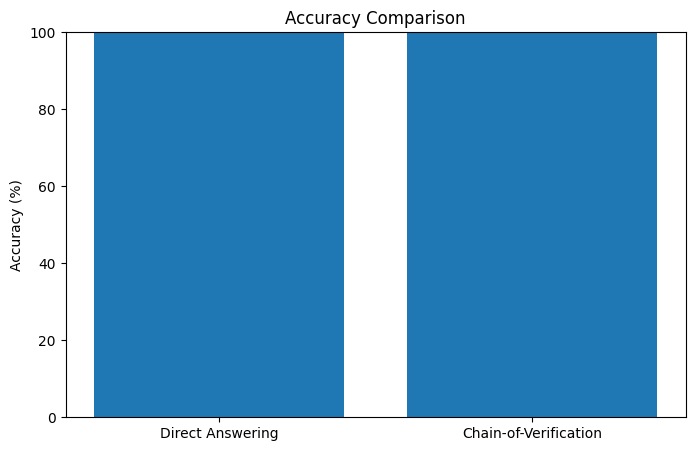

In [ ]:
methods = [
    "Direct Answering",
    "Chain-of-Verification"
]

accuracies = [
    direct_accuracy,
    verified_accuracy
]

plt.figure(figsize=(8, 5))

plt.bar(methods, accuracies)

plt.title("Accuracy Comparison")

plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)

plt.show()

In [ ]:
def classify_change(row):

    direct = row["direct_correct"]

    verified = row["verified_correct"]


    if direct == False and verified == True:
        return "Error Corrected"


    elif direct == False and verified == False:
        return "Error Not Corrected"


    elif direct == True and verified == True:
        return "Correct in Both"


    elif direct == True and verified == False:
        return "Made Incorrect"

In [ ]:
df["comparison"] = df.apply(
    classify_change,
    axis=1
)

In [ ]:
comparison_counts = df["comparison"].value_counts()

comparison_counts

,count
comparison,
Correct in Both,50


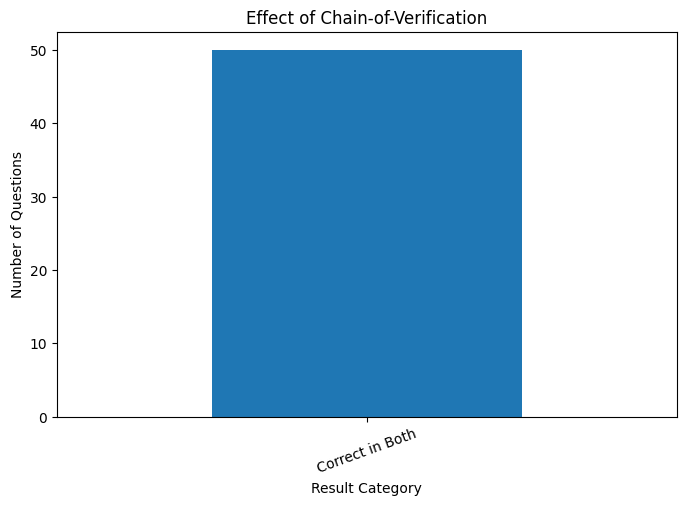

In [ ]:
comparison_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title(
    "Effect of Chain-of-Verification"
)

plt.xlabel("Result Category")

plt.ylabel("Number of Questions")

plt.xticks(rotation=20)

plt.show()

In [ ]:
category_results = []

for category in df["category"].unique():

    category_df = df[
        df["category"] == category
    ]

    direct_acc = (
        category_df["direct_correct"].mean() * 100
    )

    verified_acc = (
        category_df["verified_correct"].mean() * 100
    )


    category_results.append({
        "Category": category,
        "Direct Accuracy": direct_acc,
        "CoVe Accuracy": verified_acc
    })

In [ ]:
category_df = pd.DataFrame(
    category_results
)

category_df

,Category,Direct Accuracy,CoVe Accuracy
0,Geography,100.0,100.0
1,Science,100.0,100.0
2,Literature,100.0,100.0
3,History,100.0,100.0
4,Art,100.0,100.0
5,Mathematics,100.0,100.0
6,General Knowledge,100.0,100.0
7,Biology,100.0,100.0


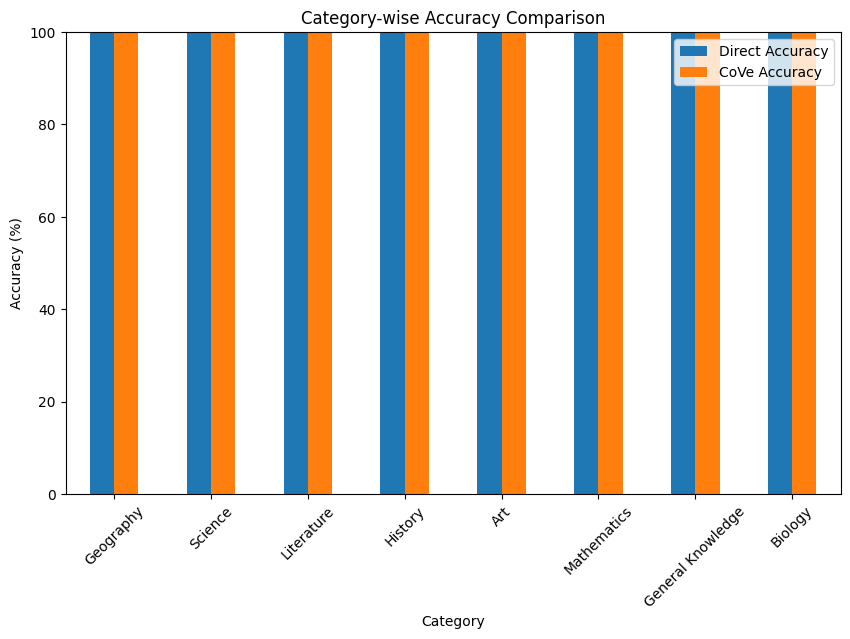

In [ ]:
category_df.plot(
    x="Category",
    y=[
        "Direct Accuracy",
        "CoVe Accuracy"
    ],
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Category-wise Accuracy Comparison"
)

plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)

plt.xticks(rotation=45)

plt.show()

In [ ]:
df.to_csv(
    "cove_experiment_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [ ]:
from google.colab import files

files.download(
    "cove_experiment_results.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
test_questions = [
    {
        "question": "What year did Albert Einstein win the Nobel Prize for his theory of relativity?",
        "ground_truth": "The premise is incorrect. Albert Einstein did not receive the Nobel Prize for relativity; he received the Nobel Prize for his discovery of the law of the photoelectric effect."
    },
    {
        "question": "Who was the first President of the United States to land on the Moon?",
        "ground_truth": "No President of the United States has ever landed on the Moon."
    }
]

In [ ]:
# ============================================================
# INTERACTIVE DASHBOARD (no ipywidgets needed)
# Uses: call_llm, get_direct_answer, get_draft_answer,
#       generate_verification_questions, answer_verification_questions,
#       generate_final_answer, evaluate_answer, df, test_questions
# ============================================================
import json, os
import pandas as pd
from IPython.display import display, HTML, JSON

try:
    from google.colab import output as colab_output
    IN_COLAB = True
except Exception:
    IN_COLAB = False

REQUIRED_COLS = [
    "id", "question", "ground_truth", "category",
    "direct_answer", "draft_answer", "verification_questions",
    "verification_answers", "verified_answer",
    "direct_correct", "verified_correct", "comparison",
]


def load_results():
    """Results DataFrame from memory, else from the saved CSV, else None."""
    candidate = globals().get("df")
    if candidate is not None and all(c in candidate.columns for c in REQUIRED_COLS):
        return candidate.copy()

    path = "cove_experiment_results.csv"
    if os.path.exists(path):
        saved = pd.read_csv(path)
        if all(c in saved.columns for c in REQUIRED_COLS):
            for c in ["direct_correct", "verified_correct"]:
                saved[c] = saved[c].astype(str).str.lower().eq("true")
            return saved
    return None


# ---------- Python side: called from the page's JavaScript ----------
def _cove_step(step, payload_json):
    try:
        p = json.loads(payload_json)

        if step == "direct":
            result = get_direct_answer(p["q"])
        elif step == "draft":
            result = get_draft_answer(p["q"])
        elif step == "vq":
            result = generate_verification_questions(p["q"], p["draft"])
        elif step == "va":
            result = answer_verification_questions(p["vq"])
        elif step == "final":
            result = generate_final_answer(p["q"], p["draft"], p["vq"], p["va"])
        elif step == "grade":
            verdict = evaluate_answer(p["q"], p["truth"], p["answer"])
            if verdict is None:
                result = None
            else:
                v = verdict.upper()
                result = ("CORRECT" in v) and ("INCORRECT" not in v)
        else:
            return JSON({"error": f"unknown step: {step}"})

        return JSON({"result": result})

    except Exception as e:
        return JSON({"error": str(e)})


if IN_COLAB:
    colab_output.register_callback("cove_step", _cove_step)


# ---------- Data handed to the page ----------
res = load_results()
rows = json.loads(res.to_json(orient="records")) if res is not None else []

default_tests = [
    {"question": "What year did Albert Einstein win the Nobel Prize for his theory of relativity?",
     "ground_truth": "The premise is incorrect. Einstein won the Nobel Prize for the photoelectric effect, not relativity."},
    {"question": "Who was the first President of the United States to land on the Moon?",
     "ground_truth": "No President of the United States has ever landed on the Moon."},
]
tests = list(globals().get("test_questions", default_tests))

DATA = {"rows": rows, "tests": tests, "inColab": IN_COLAB}
data_json = json.dumps(DATA).replace("</", "<\\/")


HTML_TEMPLATE = r"""
<style>
#cove-dash{font-family:-apple-system,Segoe UI,Roboto,sans-serif;color:#1f2328;background:#fff;
  border:1px solid #d0d7de;border-radius:10px;padding:16px;max-width:1150px}
#cove-dash *{box-sizing:border-box}
#cove-dash h2{margin:0 0 12px}
#cove-dash .tabs{display:flex;gap:6px;border-bottom:2px solid #d0d7de;margin-bottom:14px;flex-wrap:wrap}
#cove-dash .tab{padding:8px 14px;border:none;background:none;cursor:pointer;font-size:14px;
  border-bottom:3px solid transparent;margin-bottom:-2px;color:#57606a}
#cove-dash .tab.active{color:#0969da;border-bottom-color:#0969da;font-weight:600}
#cove-dash .panel{display:none}
#cove-dash .panel.active{display:block}
#cove-dash textarea,#cove-dash input[type=text],#cove-dash select{width:100%;padding:8px;font-size:14px;
  border:1px solid #d0d7de;border-radius:6px;margin:4px 0 8px;background:#fff;color:#1f2328;font-family:inherit}
#cove-dash button.run{background:#0969da;color:#fff;border:none;border-radius:6px;padding:9px 18px;
  font-size:14px;cursor:pointer}
#cove-dash button.run:disabled{background:#8c959f;cursor:wait}
#cove-dash .row{display:flex;gap:10px;flex-wrap:wrap;align-items:flex-end}
#cove-dash .row>div{flex:1;min-width:180px}
#cove-dash .kpis{display:flex;gap:12px;flex-wrap:wrap;margin-bottom:14px}
#cove-dash .kpi{flex:1;min-width:150px;background:#f6f8fa;border-left:6px solid #0969da;border-radius:8px;padding:12px 14px}
#cove-dash .kpi .l{font-size:11px;text-transform:uppercase;letter-spacing:.5px;color:#57606a}
#cove-dash .kpi .v{font-size:28px;font-weight:700}
#cove-dash .kpi .s{font-size:12px;color:#57606a}
#cove-dash .blk{background:#f6f8fa;border:1px solid #d0d7de;border-radius:8px;padding:10px 14px;margin:8px 0}
#cove-dash .blk .t{font-size:11px;font-weight:700;color:#57606a;text-transform:uppercase;letter-spacing:.5px;margin-bottom:4px}
#cove-dash .blk .b{white-space:pre-wrap;font-size:14px;line-height:1.5}
#cove-dash .blk.truth{background:#ddf4ff;border-color:#54aeff}
#cove-dash .blk.direct{background:#fff8c5;border-color:#d4a72c}
#cove-dash .blk.final{background:#dafbe1;border-color:#2da44e}
#cove-dash .badge{display:inline-block;color:#fff;padding:2px 9px;border-radius:10px;font-size:12px}
#cove-dash .status{color:#57606a;font-size:14px;padding:6px 0;min-height:24px}
#cove-dash .bar-wrap{display:flex;align-items:center;gap:8px;margin:6px 0;font-size:13px}
#cove-dash .bar-label{width:150px;flex-shrink:0}
#cove-dash .bar-track{flex:1;background:#eaeef2;border-radius:5px;height:20px;position:relative}
#cove-dash .bar{height:100%;border-radius:5px}
#cove-dash .bar-val{width:70px;text-align:right;flex-shrink:0}
#cove-dash table{border-collapse:collapse;width:100%;font-size:13px}
#cove-dash th{text-align:left;padding:8px;border-bottom:2px solid #d0d7de;background:#f6f8fa;position:sticky;top:0}
#cove-dash td{padding:7px 8px;border-bottom:1px solid #eaeef2;vertical-align:top}
#cove-dash tr.click{cursor:pointer}
#cove-dash tr.click:hover{background:#f0f6ff}
#cove-dash .scroll{max-height:360px;overflow:auto;border:1px solid #d0d7de;border-radius:8px}
#cove-dash .muted{color:#57606a;font-size:13px}
#cove-dash .sec{margin:18px 0 6px;font-size:15px;font-weight:600}
</style>

<div id="cove-dash">
  <h2>Chain-of-Verification Dashboard</h2>
  <div class="tabs">
    <button class="tab active" data-tab="live">🔬 Live CoVe</button>
    <button class="tab" data-tab="overview">📈 Overview</button>
    <button class="tab" data-tab="explorer">🔎 Explorer</button>
    <button class="tab" data-tab="stress">🧪 Stress Test</button>
  </div>

  <div class="panel active" id="p-live">
    <div class="muted">Each run makes about 4 to 6 API calls. With your 5 s rate limiter expect roughly 25 to 40 seconds.</div>
    <label>Question</label>
    <textarea id="live-q" rows="2">Who was the first President of the United States to land on the Moon?</textarea>
    <label>Ground truth (optional, to auto-grade)</label>
    <input type="text" id="live-truth" placeholder="e.g. No President has ever landed on the Moon.">
    <label><input type="checkbox" id="live-direct" checked> Also get a direct answer for comparison (+1 call)</label><br><br>
    <button class="run" id="live-run">▶ Run Chain-of-Verification</button>
    <div class="status" id="live-status"></div>
    <div id="live-out"></div>
    <div id="live-hist"></div>
  </div>

  <div class="panel" id="p-overview"><div id="overview-out"></div></div>

  <div class="panel" id="p-explorer">
    <div class="row">
      <div><label>Category</label><select id="ex-cat"></select></div>
      <div><label>Outcome</label><select id="ex-out">
        <option>All</option><option>Error Corrected</option><option>Correct in Both</option>
        <option>Error Not Corrected</option><option>Made Incorrect</option></select></div>
      <div><label>Search</label><input type="text" id="ex-search" placeholder="Search..."></div>
    </div>
    <div id="ex-table"></div>
    <div id="ex-detail"></div>
  </div>

  <div class="panel" id="p-stress">
    <div class="muted">False-premise questions are where models tend to hallucinate. Pick one and compare direct answering with CoVe.</div>
    <label>Question</label>
    <select id="st-pick"></select>
    <button class="run" id="st-run">🧪 Run direct vs CoVe</button>
    <div class="status" id="st-status"></div>
    <div id="st-out"></div>
  </div>
</div>

<script>
(function(){
const DATA = __DATA__;
const root = document.getElementById('cove-dash');
const $ = id => root.querySelector('#'+id);
const COLORS = {"Error Corrected":"#1a7f37","Correct in Both":"#0969da",
                "Error Not Corrected":"#9a6700","Made Incorrect":"#cf222e"};

function esc(s){
  return String(s==null?'':s).replace(/[&<>"']/g,
    c=>({'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;',"'":'&#39;'}[c]));
}
function block(title, body, cls){
  return '<div class="blk '+(cls||'')+'"><div class="t">'+esc(title)+
         '</div><div class="b">'+(body?esc(body):'<i>(no response)</i>')+'</div></div>';
}
function badge(text, color){ return '<span class="badge" style="background:'+color+'">'+esc(text)+'</span>'; }
function mark(ok){ return ok===null||ok===undefined ? '' : (ok?' ✅':' ❌'); }

/* ---------- tabs ---------- */
root.querySelectorAll('.tab').forEach(btn=>{
  btn.addEventListener('click',()=>{
    root.querySelectorAll('.tab').forEach(b=>b.classList.remove('active'));
    root.querySelectorAll('.panel').forEach(p=>p.classList.remove('active'));
    btn.classList.add('active');
    $('p-'+btn.dataset.tab).classList.add('active');
  });
});

/* ---------- Python bridge ---------- */
async function call(step, payload){
  if(!(window.google && google.colab && google.colab.kernel)){
    throw new Error('Not connected to a Colab kernel. Run the cell in Google Colab.');
  }
  const r = await google.colab.kernel.invokeFunction('cove_step',[step, JSON.stringify(payload)],{});
  const d = r.data['application/json'];
  if(d.error) throw new Error(d.error);
  return d.result;
}

/* Runs the full pipeline, updating status text and returning a record */
async function runCoVe(q, truth, withDirect, setStatus){
  const rec = {question:q, truth:truth};
  if(withDirect){ setStatus('⏳ Getting direct answer...'); rec.direct = await call('direct',{q}); }
  setStatus('⏳ Step 1/4: drafting an answer...');            rec.draft = await call('draft',{q});
  setStatus('⏳ Step 2/4: generating verification questions...'); rec.vq = await call('vq',{q, draft:rec.draft});
  setStatus('⏳ Step 3/4: answering verification questions...');  rec.va = await call('va',{vq:rec.vq});
  setStatus('⏳ Step 4/4: producing the final verified answer...'); rec.final = await call('final',{q, draft:rec.draft, vq:rec.vq, va:rec.va});
  rec.directOk = rec.verifiedOk = null;
  if(truth){
    setStatus('⏳ Grading against ground truth...');
    if(rec.direct) rec.directOk = await call('grade',{q, truth, answer:rec.direct});
    if(rec.final)  rec.verifiedOk = await call('grade',{q, truth, answer:rec.final});
  }
  rec.changed = (rec.draft||'').trim().toLowerCase() !== (rec.final||'').trim().toLowerCase();
  return rec;
}

function renderRecord(rec){
  let h = '';
  if(rec.truth) h += block('Expected (ground truth)', rec.truth, 'truth');
  if(rec.direct !== undefined) h += block('Direct answer (no verification)'+mark(rec.directOk), rec.direct, 'direct');
  h += block('Step 1: Draft answer', rec.draft);
  h += block('Step 2: Verification questions', rec.vq);
  h += block('Step 3: Verification answers', rec.va);
  h += block('Step 4: Final verified answer'+mark(rec.verifiedOk), rec.final, 'final');
  h += rec.changed ? badge('Verification CHANGED the draft answer','#8250df')
                   : badge('Verification kept the draft answer','#57606a');
  return h;
}

/* ---------- Live tab ---------- */
const history = [];
$('live-run').addEventListener('click', async ()=>{
  const q = $('live-q').value.trim();
  if(!q){ $('live-status').textContent='⚠️ Please enter a question.'; return; }
  const btn = $('live-run'); btn.disabled = true; $('live-out').innerHTML='';
  const setStatus = t => { $('live-status').textContent = t; };
  try{
    const rec = await runCoVe(q, $('live-truth').value.trim(), $('live-direct').checked, setStatus);
    $('live-out').innerHTML = renderRecord(rec);
    history.push(rec);
    let rows = history.map(r=>'<tr><td>'+esc(r.question)+'</td><td>'+esc(r.direct===undefined?'':r.direct)+
      '</td><td>'+esc(r.draft)+'</td><td>'+esc(r.final)+'</td><td>'+(r.changed?'yes':'no')+'</td></tr>').join('');
    $('live-hist').innerHTML = '<div class="sec">Session history</div><div class="scroll"><table><thead><tr>'+
      '<th>Question</th><th>Direct</th><th>Draft</th><th>Final</th><th>Changed?</th></tr></thead><tbody>'+rows+'</tbody></table></div>';
    setStatus('✅ Done.');
  }catch(e){
    setStatus('❌ Error: '+e.message);
  }finally{ btn.disabled = false; }
});

/* ---------- Overview tab ---------- */
function mean(arr){ return arr.length ? arr.reduce((a,b)=>a+b,0)/arr.length : 0; }
function bar(label, pct, color, valText){
  return '<div class="bar-wrap"><div class="bar-label">'+esc(label)+'</div><div class="bar-track"><div class="bar" style="width:'+
    Math.max(0,Math.min(100,pct))+'%;background:'+color+'"></div></div><div class="bar-val">'+esc(valText)+'</div></div>';
}
function renderOverview(){
  const R = DATA.rows;
  if(!R.length){
    $('overview-out').innerHTML = '<p style="color:#cf222e">No complete results found. Run the experiment cells above (or save cove_experiment_results.csv), then re-run this cell.</p>';
    return;
  }
  const d = mean(R.map(r=>r.direct_correct?1:0))*100;
  const v = mean(R.map(r=>r.verified_correct?1:0))*100;
  const counts = {};
  R.forEach(r=>{ counts[r.comparison]=(counts[r.comparison]||0)+1; });
  const fixed = counts['Error Corrected']||0, broke = counts['Made Incorrect']||0;
  const diff = v-d;
  let h = '<div class="kpis">'+
    '<div class="kpi" style="border-color:#57606a"><div class="l">Questions</div><div class="v">'+R.length+'</div></div>'+
    '<div class="kpi" style="border-color:#d4a72c"><div class="l">Direct accuracy</div><div class="v">'+d.toFixed(1)+'%</div><div class="s">no verification</div></div>'+
    '<div class="kpi" style="border-color:#2da44e"><div class="l">CoVe accuracy</div><div class="v">'+v.toFixed(1)+'%</div><div class="s">with verification</div></div>'+
    '<div class="kpi" style="border-color:#8250df"><div class="l">Change</div><div class="v">'+(diff>=0?'+':'')+diff.toFixed(1)+' pts</div><div class="s">'+fixed+' fixed · '+broke+' broken</div></div></div>';

  h += '<div class="sec">Overall accuracy</div>'+
       bar('Direct', d, '#d4a72c', d.toFixed(1)+'%')+bar('Chain-of-Verification', v, '#2da44e', v.toFixed(1)+'%');

  h += '<div class="sec">Effect of Chain-of-Verification</div>';
  ['Error Corrected','Correct in Both','Error Not Corrected','Made Incorrect'].forEach(k=>{
    const n = counts[k]||0;
    h += bar(k, n/R.length*100, COLORS[k], n+' / '+R.length);
  });

  const cats = [...new Set(R.map(r=>r.category))].sort();
  h += '<div class="sec">Accuracy by category</div><div class="scroll"><table><thead><tr><th>Category</th><th>Questions</th>'+
       '<th>Direct %</th><th>CoVe %</th><th>Change</th></tr></thead><tbody>';
  cats.forEach(c=>{
    const sub = R.filter(r=>r.category===c);
    const dd = mean(sub.map(r=>r.direct_correct?1:0))*100, vv = mean(sub.map(r=>r.verified_correct?1:0))*100;
    const ch = vv-dd;
    h += '<tr><td>'+esc(c)+'</td><td>'+sub.length+'</td><td>'+dd.toFixed(1)+'</td><td>'+vv.toFixed(1)+'</td><td style="color:'+
         (ch>0?'#1a7f37':ch<0?'#cf222e':'#57606a')+'">'+(ch>0?'+':'')+ch.toFixed(1)+'</td></tr>';
  });
  h += '</tbody></table></div>';
  $('overview-out').innerHTML = h;
}

/* ---------- Explorer tab ---------- */
function initExplorer(){
  const R = DATA.rows;
  if(!R.length){
    $('ex-table').innerHTML = '<p style="color:#cf222e">No complete results found. Run the experiment cells above first, then re-run this cell.</p>';
    return;
  }
  const cats = ['All'].concat([...new Set(R.map(r=>r.category))].sort());
  $('ex-cat').innerHTML = cats.map(c=>'<option>'+esc(c)+'</option>').join('');
  ['ex-cat','ex-out'].forEach(id=>$(id).addEventListener('change', renderExplorer));
  $('ex-search').addEventListener('input', renderExplorer);
  renderExplorer();
}
function renderExplorer(){
  const R = DATA.rows, cat = $('ex-cat').value, out = $('ex-out').value, term = $('ex-search').value.trim().toLowerCase();
  const F = R.filter(r=>
    (cat==='All'||r.category===cat) && (out==='All'||r.comparison===out) &&
    (!term || [r.question,r.direct_answer,r.verified_answer,r.ground_truth].some(x=>String(x==null?'':x).toLowerCase().includes(term))));
  if(!F.length){ $('ex-table').innerHTML='<p>No questions match these filters.</p>'; $('ex-detail').innerHTML=''; return; }
  const body = F.map(r=>'<tr class="click" data-id="'+esc(r.id)+'"><td>'+esc(r.id)+'</td><td>'+esc(r.question)+'</td><td>'+esc(r.category)+
    '</td><td>'+esc(r.ground_truth)+'</td><td>'+esc(r.direct_answer)+mark(r.direct_correct)+'</td><td>'+esc(r.verified_answer)+mark(r.verified_correct)+
    '</td><td>'+badge(r.comparison, COLORS[r.comparison]||'#57606a')+'</td></tr>').join('');
  $('ex-table').innerHTML = '<div class="scroll"><table><thead><tr><th>ID</th><th>Question</th><th>Category</th><th>Truth</th><th>Direct</th><th>CoVe</th><th>Outcome</th></tr></thead><tbody>'+
    body+'</tbody></table></div><div class="muted">Showing '+F.length+' of '+R.length+' questions. Click a row for details.</div>';
  $('ex-table').querySelectorAll('tr.click').forEach(tr=>{
    tr.addEventListener('click',()=>showDetail(tr.dataset.id));
  });
  showDetail(F[0].id);
}
function showDetail(id){
  const r = DATA.rows.find(x=>String(x.id)===String(id));
  if(!r) return;
  $('ex-detail').innerHTML =
    '<h3 style="margin:14px 0 6px">#'+esc(r.id)+': '+esc(r.question)+'</h3>'+
    badge(r.category,'#57606a')+' '+badge(r.comparison, COLORS[r.comparison]||'#57606a')+
    block('Ground truth', r.ground_truth, 'truth')+
    block('Direct answer'+mark(r.direct_correct), r.direct_answer, 'direct')+
    block('CoVe: draft answer', r.draft_answer)+
    block('CoVe: verification questions', r.verification_questions)+
    block('CoVe: verification answers', r.verification_answers)+
    block('CoVe: final verified answer'+mark(r.verified_correct), r.verified_answer, 'final');
}

/* ---------- Stress tab ---------- */
$('st-pick').innerHTML = DATA.tests.map((t,i)=>'<option value="'+i+'">'+esc(t.question)+'</option>').join('');
$('st-run').addEventListener('click', async ()=>{
  const t = DATA.tests[parseInt($('st-pick').value,10)];
  const btn = $('st-run'); btn.disabled = true; $('st-out').innerHTML='';
  const setStatus = s => { $('st-status').textContent = s; };
  try{
    const rec = await runCoVe(t.question, t.ground_truth, true, setStatus);
    $('st-out').innerHTML = renderRecord(rec);
    setStatus('✅ Done.');
  }catch(e){ setStatus('❌ Error: '+e.message); }
  finally{ btn.disabled = false; }
});

renderOverview();
initExplorer();
})();
</script>
"""

display(HTML(HTML_TEMPLATE.replace("__DATA__", data_json)))

if not IN_COLAB:
    print("Note: not running in Colab, so the Live and Stress tabs cannot call the model.")
elif res is None:
    print("Note: no complete results found, so Overview and Explorer will be empty. "
          "Run the experiment cells (or save cove_experiment_results.csv) and re-run this cell.")

Direct Answering vs. Chain-of-Verification

To further examine the effectiveness of the Chain-of-Verification (CoVe) approach, an additional evaluation was conducted by comparing it with direct LLM-based answering.

A dataset of 8 factual questions was created, covering different categories and difficulty levels, including:
- Geography and general knowledge
- Science and biology
- Historical facts
- Ambiguous questions
- Questions containing false premises

Both direct answering and the CoVe approach were tested on the same questions. Their responses were evaluated against reference answers using an LLM-as-a-Judge approach.

The objective of this experiment is to compare factual correctness and examine how the verification process handles potentially misleading, ambiguous, or incorrect assumptions.

In [ ]:

# ============================================================
# IMPROVED EVALUATION DATASET
# ============================================================

evaluation_cases = [
    {
        "id": 1,
        "question": "What is the largest desert in the world?",
        "ground_truth": "The Antarctic Desert. The Sahara is the largest hot desert, but Antarctica is the largest desert overall.",
        "category": "Geography",
        "difficulty": "Tricky"
    },
    {
        "id": 2,
        "question": "What is the capital of South Africa?",
        "ground_truth": "South Africa has three capital cities: Pretoria (executive), Cape Town (legislative), and Bloemfontein (judicial).",
        "category": "Geography",
        "difficulty": "Ambiguous"
    },
    {
        "id": 3,
        "question": "Which US President was the first to land on the Moon?",
        "ground_truth": "No US President has ever landed on the Moon. The question contains a false premise.",
        "category": "History",
        "difficulty": "False Premise"
    },
    {
        "id": 4,
        "question": "In which year did Albert Einstein receive the Nobel Prize for his theory of relativity?",
        "ground_truth": "The premise is incorrect. Einstein received the 1921 Nobel Prize in Physics for his explanation of the photoelectric effect, not for relativity. The prize was presented in 1922.",
        "category": "Science",
        "difficulty": "False Premise"
    },
    {
        "id": 5,
        "question": "Does water always boil at exactly 100 degrees Celsius?",
        "ground_truth": "No. Water boils at approximately 100 degrees Celsius at standard atmospheric pressure (1 atmosphere). The boiling point changes with pressure.",
        "category": "Science",
        "difficulty": "Conceptual"
    },
    {
        "id": 6,
        "question": "Can the Great Wall of China be seen with the naked eye from the Moon?",
        "ground_truth": "No. The Great Wall of China cannot be seen with the naked eye from the Moon.",
        "category": "Science",
        "difficulty": "Tricky"
    },
    {
        "id": 7,
        "question": "How many hearts does an octopus have?",
        "ground_truth": "An octopus has three hearts: two pump blood to the gills and one pumps blood to the rest of the body.",
        "category": "Biology",
        "difficulty": "Conceptual"
    },
    {
        "id": 8,
        "question": "What is the capital of Australia?",
        "ground_truth": "Canberra.",
        "category": "Geography",
        "difficulty": "Easy"
    }
]

evaluation_df = pd.DataFrame(evaluation_cases)

print("Evaluation dataset created.")
print("Total questions:", len(evaluation_df))
display(evaluation_df)


Evaluation dataset created.
Total questions: 8


,id,question,ground_truth,category,difficulty
0,1,What is the largest desert in the world?,The Antarctic Desert. The Sahara is the larges...,Geography,Tricky
1,2,What is the capital of South Africa?,South Africa has three capital cities: Pretori...,Geography,Ambiguous
2,3,Which US President was the first to land on th...,No US President has ever landed on the Moon. T...,History,False Premise
3,4,In which year did Albert Einstein receive the ...,The premise is incorrect. Einstein received th...,Science,False Premise
4,5,Does water always boil at exactly 100 degrees ...,No. Water boils at approximately 100 degrees C...,Science,Conceptual
5,6,Can the Great Wall of China be seen with the n...,No. The Great Wall of China cannot be seen wit...,Science,Tricky
6,7,How many hearts does an octopus have?,An octopus has three hearts: two pump blood to...,Biology,Conceptual
7,8,What is the capital of Australia?,Canberra.,Geography,Easy


In [ ]:

# ============================================================
# IMPROVED LLM-AS-A-JUDGE EVALUATION
# ============================================================

def evaluate_answer(question, ground_truth, model_answer):

    if not model_answer:
        return "ERROR"

    prompt = f"""
You are an independent evaluation judge.

Evaluate the factual correctness of the candidate answer.

QUESTION:
{question}

REFERENCE ANSWER:
{ground_truth}

CANDIDATE ANSWER:
{model_answer}

EVALUATION RULES:

1. Accept answers that communicate the same factual meaning.
2. Do not require identical wording.
3. Reject answers containing important factual errors.
4. Reject answers that accept a false premise.
5. For ambiguous questions, accept an answer that correctly
   explains the ambiguity.
6. Do not reward unsupported claims that contradict the
   reference answer.
7. If the answer is incomplete or materially misleading,
   mark it INCORRECT.

Return exactly one label:

CORRECT

or

INCORRECT
"""

    result = call_llm(prompt)

    if result is None:
        return "ERROR"

    result = result.strip().upper()

    if result == "CORRECT":
        return "CORRECT"
    elif result == "INCORRECT":
        return "INCORRECT"
    else:
        return "ERROR"


print("Evaluation function updated.")


Evaluation function updated.


In [ ]:

# ============================================================
# DIRECT ANSWERING VS CHAIN-OF-VERIFICATION
# ============================================================

evaluation_results = []

for _, row in evaluation_df.iterrows():

    question = row["question"]

    print(f"\nProcessing Question {row['id']}...")

    # Direct answer
    direct_answer = get_direct_answer(question)

    # Chain-of-Verification
    cove_output = chain_of_verification(question)

    verified_answer = cove_output["verified_answer"]

    evaluation_results.append({
        "id": row["id"],
        "question": question,
        "category": row["category"],
        "difficulty": row["difficulty"],
        "ground_truth": row["ground_truth"],
        "direct_answer": direct_answer,
        "draft_answer": cove_output["draft_answer"],
        "verification_questions": cove_output["verification_questions"],
        "verification_answers": cove_output["verification_answers"],
        "verified_answer": verified_answer
    })

    print("Direct answer:", direct_answer)
    print("Verified answer:", verified_answer)

results_df = pd.DataFrame(evaluation_results)

print("\nAnswer generation completed.")



Processing Question 1...
Direct answer: Antarctic Desert
Verified answer: The Antarctic Desert is the largest desert in the world.

Processing Question 2...
Direct answer: South Africa has three capital cities: Pretoria (executive), Cape Town (legislative), and Bloemfontein (judicial).
Verified answer: South Africa has three capital cities: **Pretoria** (executive), **Cape Town** (legislative), and **Bloemfontein** (judicial).

Processing Question 3...
Direct answer: No US President has ever landed on the Moon.
Verified answer: No US President has ever landed on the Moon. (Neil Armstrong and Buzz Aldrin were the first humans to land on the Moon, neither of whom was President.)

Processing Question 4...
Direct answer: Albert Einstein did not receive the Nobel Prize for his theory of relativity. He was awarded the 1921 Nobel Prize in Physics "for his services to Theoretical Physics, and especially for his discovery of the law of the photoelectric effect."
Verified answer: Albert Einstei

In [ ]:

# ============================================================
# EVALUATE BOTH METHODS
# ============================================================

direct_scores = []
cove_scores = []

for _, row in results_df.iterrows():

    print(f"Evaluating Question {row['id']}...")

    direct_result = evaluate_answer(
        row["question"],
        row["ground_truth"],
        row["direct_answer"]
    )

    cove_result = evaluate_answer(
        row["question"],
        row["ground_truth"],
        row["verified_answer"]
    )

    direct_scores.append(direct_result)
    cove_scores.append(cove_result)

results_df["direct_result"] = direct_scores
results_df["cove_result"] = cove_scores

# Exclude failed API evaluations from the accuracy denominator
valid_direct = results_df["direct_result"].isin(
    ["CORRECT", "INCORRECT"]
)

valid_cove = results_df["cove_result"].isin(
    ["CORRECT", "INCORRECT"]
)

direct_accuracy = (
    (results_df.loc[valid_direct, "direct_result"] == "CORRECT").mean()
    * 100
)

cove_accuracy = (
    (results_df.loc[valid_cove, "cove_result"] == "CORRECT").mean()
    * 100
)

print("\n========== EVALUATION RESULTS ==========")

print("Direct accuracy:", round(direct_accuracy, 2), "%")
print("CoVe accuracy:", round(cove_accuracy, 2), "%")

print("Direct valid evaluations:", valid_direct.sum())
print("CoVe valid evaluations:", valid_cove.sum())

print(
    "Accuracy difference:",
    round(cove_accuracy - direct_accuracy, 2),
    "percentage points"
)

display(
    results_df[
        ["id", "difficulty", "direct_result", "cove_result"]
    ]
)


Evaluating Question 1...
Evaluating Question 2...
Evaluating Question 3...
Evaluating Question 4...
Evaluating Question 5...
Evaluating Question 6...
Evaluating Question 7...
Evaluating Question 8...

========== EVALUATION RESULTS ==========
Direct accuracy: 100.0 %
CoVe accuracy: 100.0 %
Direct valid evaluations: 7
CoVe valid evaluations: 8
Accuracy difference: 0.0 percentage points


,id,difficulty,direct_result,cove_result
0,1,Tricky,CORRECT,CORRECT
1,2,Ambiguous,CORRECT,CORRECT
2,3,False Premise,CORRECT,CORRECT
3,4,False Premise,CORRECT,CORRECT
4,5,Conceptual,ERROR,CORRECT
5,6,Tricky,CORRECT,CORRECT
6,7,Conceptual,CORRECT,CORRECT
7,8,Easy,CORRECT,CORRECT




### Conclusion

This project demonstrates the implementation of Chain-of-Verification (CoVe) using Google's Gemini API to improve the reliability of factual responses generated by large language models.

The approach follows a multi-step process involving:
1. Generating an initial draft answer.
2. Formulating independent verification questions based on the draft.
3. Answering the verification questions.
4. Producing a final answer using the verification information.

An additional experiment compared direct answering with CoVe across 8 factual questions. Both approaches achieved 100% accuracy among their valid evaluations. Direct answering had 7 valid evaluations, while CoVe had 8.

Although both approaches achieved the same measured accuracy in this experiment, the results demonstrate the implementation of a structured verification workflow. They do not establish that CoVe consistently outperforms direct answering.

### Limitations

- The additional evaluation dataset contains only 8 questions, which limits the generalizability of the results.
- The LLM-as-a-Judge approach relies on Gemini to evaluate the generated responses and may introduce evaluation bias.
- API errors resulted in one invalid direct-answer evaluation, which was excluded from the accuracy calculation.
- The verification process does not guarantee that every factual error will be detected or corrected.
- The system does not currently use external knowledge sources or document retrieval to independently verify claims.

### Future Scope

- Expand the evaluation dataset with more diverse and challenging factual questions.
- Introduce independent evaluation using human-reviewed reference answers.
- Integrate external knowledge sources and retrieval-based verification.
- Explore more robust evaluation metrics and compare different LLM models.

Overall, this project explores how structured verification techniques can be incorporated into LLM workflows to encourage more reliable and factually consistent responses.